In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math

# Set seaborn style for better looking charts
sns.set_theme(style="darkgrid")

def load_replay(filepath):
    print(f"Loading {filepath}...")
    try:
        # Added utf-8 encoding for safety
        with open(filepath, 'r', encoding='utf-8') as f:
            html_content = f.read()
        
        # Chop off everything before the JSON payload
        raw_tail = html_content.split('window.kaggle = ', 1)[1]
        
        # Chop off everything after the JSON payload
        json_string_candidate = raw_tail.split('window.kaggle.renderer', 1)[0]
        
        # Strip trailing newlines and the JavaScript semicolon so it's pure JSON
        clean_json_string = json_string_candidate.strip().rstrip(';')
        
        # Parse it!
        data = json.loads(clean_json_string)
        return data['environment']['steps']
        
    except FileNotFoundError:
        print(f"Error: Could not find the file at {filepath}. Check your relative path!")
        return None
    except Exception as e:
        # Now it will actually tell us what broke if it fails
        print(f"Failed to parse JSON from HTML: {e}")
        return None

# Make sure this path exactly matches where your script saved the file!
steps = load_replay("/home/saksham/Documents/kaggle/OrbitWars/replays/replay_match_1_2-player_seed12830.html")

if steps is not None:
    print(f"Successfully loaded {len(steps)} turns.")

Loading /home/saksham/Documents/kaggle/OrbitWars/replays/replay_match_1_2-player_seed12830.html...
Successfully loaded 160 turns.


In [2]:
economy_data = []
fleet_launches = []
seen_fleets = set()

for turn_idx, step in enumerate(steps):
    obs = step[0]['observation']
    planets = obs['planets']
    fleets = obs.get('fleets', [])
    
    p0_planet_ships = 0
    p1_planet_ships = 0
    p0_fleet_ships = 0
    p1_fleet_ships = 0
    
    # Tally Planet Economy
    for p in planets:
        owner = p[1]
        ships = p[5]
        if owner == 0: p0_planet_ships += ships
        elif owner == 1: p1_planet_ships += ships
            
    # Tally Fleet Economy & Detect New Launches
    for f in fleets:
        f_id = f[0]
        owner = f[1]
        ships = f[6]
        
        if owner == 0: p0_fleet_ships += ships
        elif owner == 1: p1_fleet_ships += ships
            
        # Detect new fleet launches (Trickle Bleed tracker)
        if f_id not in seen_fleets:
            seen_fleets.add(f_id)
            fleet_launches.append({
                'turn': turn_idx,
                'owner': owner,
                'ships': ships
            })
            
    economy_data.append({
        'turn': turn_idx,
        'P0_Planets': p0_planet_ships,
        'P1_Planets': p1_planet_ships,
        'P0_Fleets': p0_fleet_ships,
        'P1_Fleets': p1_fleet_ships,
        'P0_Total': p0_planet_ships + p0_fleet_ships,
        'P1_Total': p1_planet_ships + p1_fleet_ships
    })

df_eco = pd.DataFrame(economy_data)
df_launches = pd.DataFrame(fleet_launches)

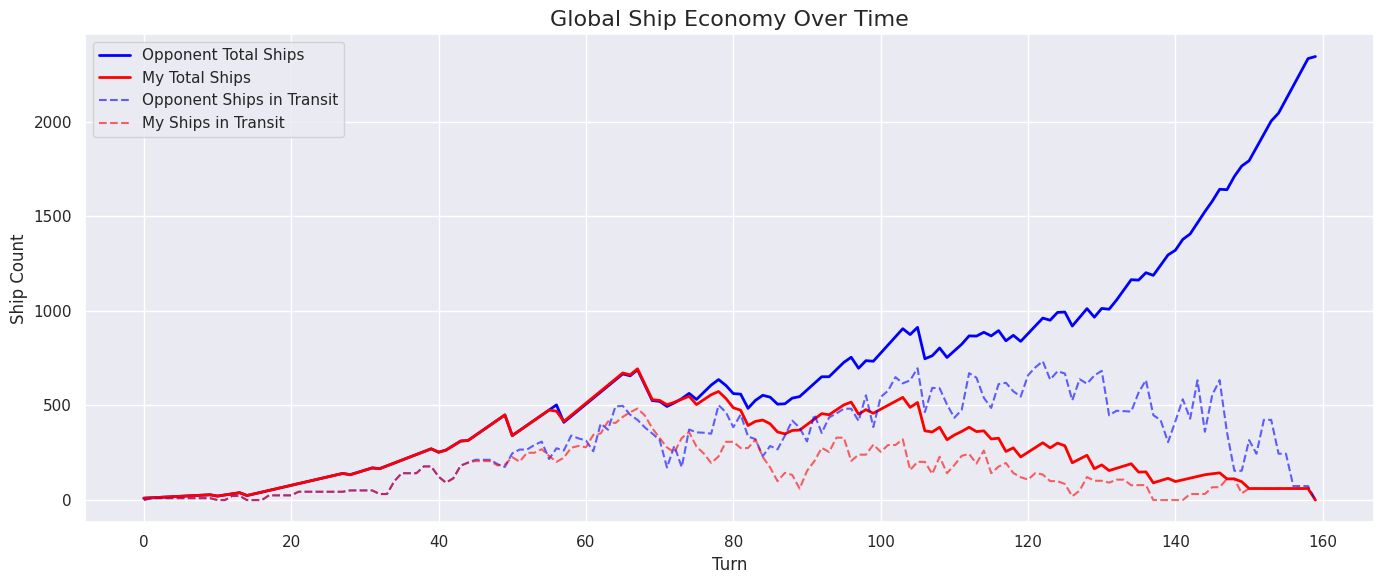

In [3]:
plt.figure(figsize=(14, 6))

plt.plot(df_eco['turn'], df_eco['P1_Total'], label='Opponent Total Ships', color='blue', linewidth=2)
plt.plot(df_eco['turn'], df_eco['P0_Total'], label='My Total Ships', color='red', linewidth=2)

plt.plot(df_eco['turn'], df_eco['P1_Fleets'], label='Opponent Ships in Transit', color='blue', linestyle='--', alpha=0.6)
plt.plot(df_eco['turn'], df_eco['P0_Fleets'], label='My Ships in Transit', color='red', linestyle='--', alpha=0.6)

plt.title('Global Ship Economy Over Time', fontsize=16)
plt.xlabel('Turn', fontsize=12)
plt.ylabel('Ship Count', fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()

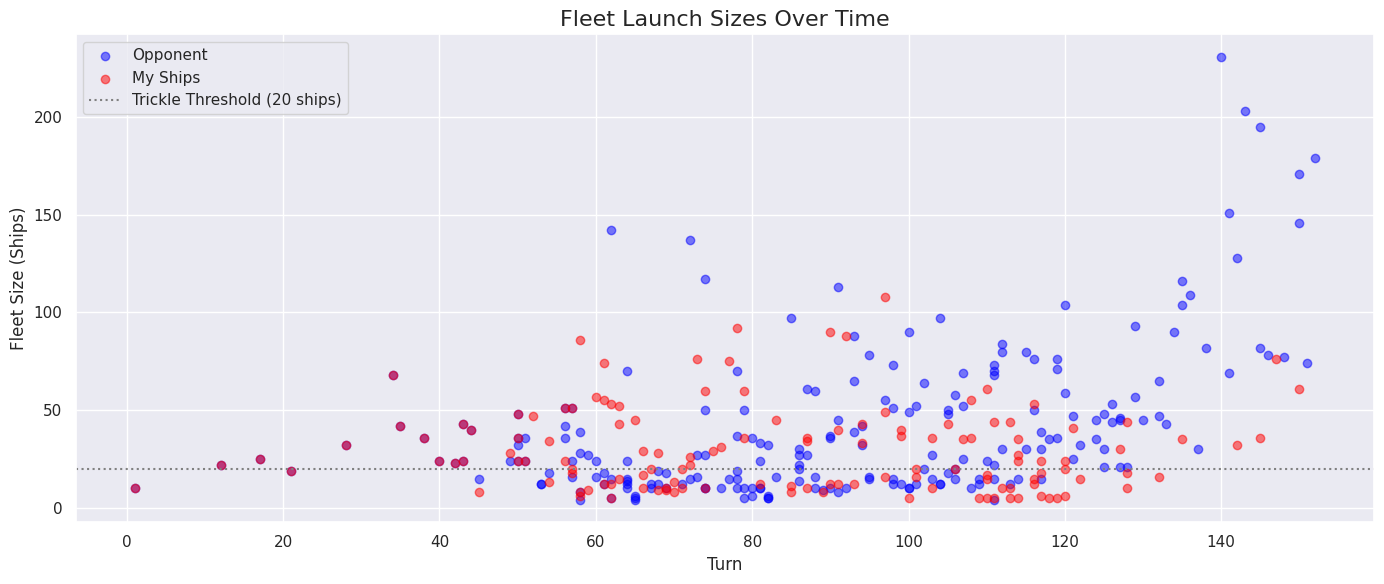

In [4]:
plt.figure(figsize=(14, 6))

# Separate launches by player
p0_launches = df_launches[df_launches['owner'] == 0]
p1_launches = df_launches[df_launches['owner'] == 1]

plt.scatter(p1_launches['turn'], p1_launches['ships'], color='blue', alpha=0.5, label='Opponent')
plt.scatter(p0_launches['turn'], p0_launches['ships'], color='red', alpha=0.5, label='My Ships')

# Add a threshold line to highlight "trickle" fleets
plt.axhline(y=20, color='gray', linestyle=':', label='Trickle Threshold (20 ships)')

plt.title('Fleet Launch Sizes Over Time', fontsize=16)
plt.xlabel('Turn', fontsize=12)
plt.ylabel('Fleet Size (Ships)', fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()

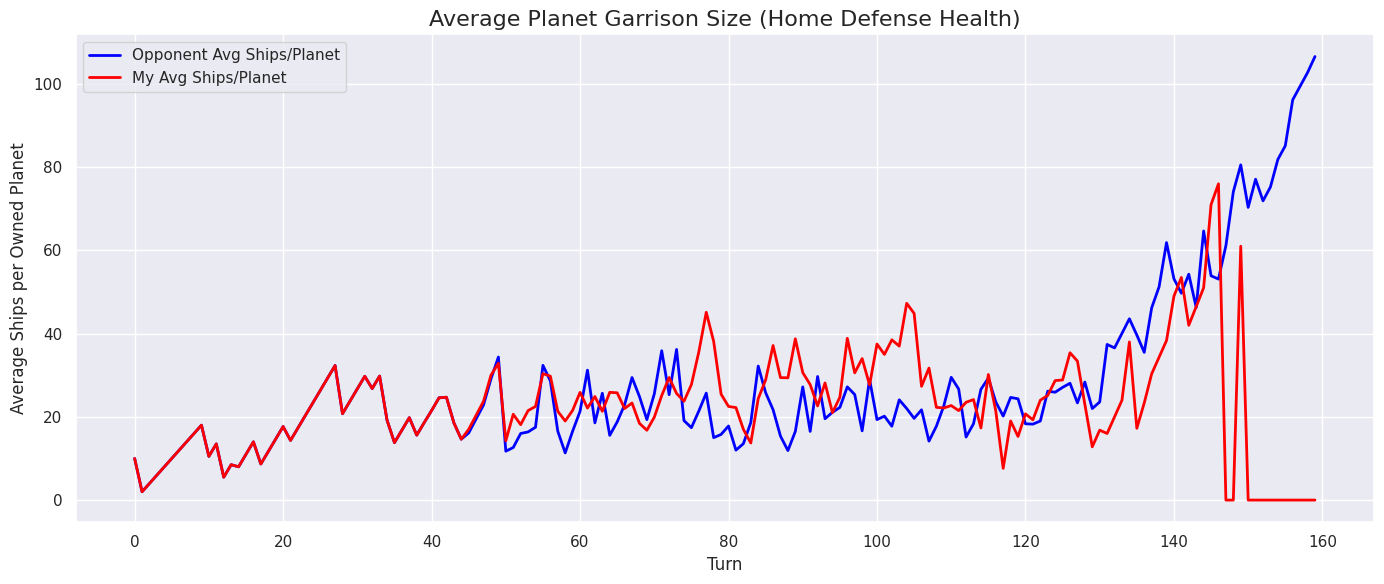

In [5]:
# Cell: Planet Garrison Health Over Time
garrison_data = []

for turn_idx, step in enumerate(steps):
    obs = step[0]['observation']
    planets = obs['planets']
    
    p0_planets = [p[5] for p in planets if p[1] == 0]
    p1_planets = [p[5] for p in planets if p[1] == 1]
    
    garrison_data.append({
        'turn': turn_idx,
        'P0_Avg_Garrison': sum(p0_planets) / len(p0_planets) if p0_planets else 0,
        'P1_Avg_Garrison': sum(p1_planets) / len(p1_planets) if p1_planets else 0,
    })

df_garrison = pd.DataFrame(garrison_data)

plt.figure(figsize=(14, 6))
plt.plot(df_garrison['turn'], df_garrison['P1_Avg_Garrison'], label='Opponent Avg Ships/Planet', color='blue', linewidth=2)
plt.plot(df_garrison['turn'], df_garrison['P0_Avg_Garrison'], label='My Avg Ships/Planet', color='red', linewidth=2)
plt.title('Average Planet Garrison Size (Home Defense Health)', fontsize=16)
plt.xlabel('Turn', fontsize=12)
plt.ylabel('Average Ships per Owned Planet', fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()

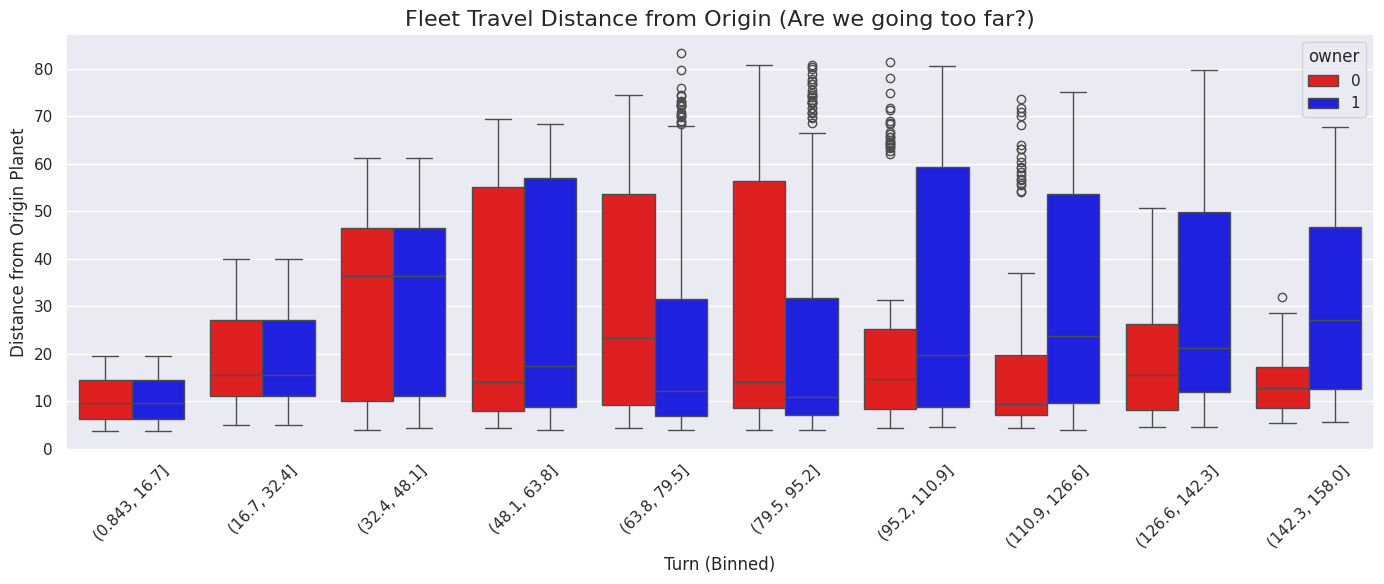

In [6]:
# Cell: Fleet Travel Distance Approximation
travel_data = []

# Get static initial planet locations for origin mapping
initial_planets = steps[0][0]['observation']['planets']
planet_coords = {p[0]: (p[2], p[3]) for p in initial_planets}

for turn_idx, step in enumerate(steps):
    obs = step[0]['observation']
    fleets = obs.get('fleets', [])
    
    for f in fleets:
        owner = f[1]
        fx, fy = f[2], f[3]
        origin_id = f[5]
        
        # Calculate distance from origin
        ox, oy = planet_coords.get(origin_id, (50, 50))
        dist_from_home = math.hypot(fx - ox, fy - oy)
        
        travel_data.append({
            'turn': turn_idx,
            'owner': owner,
            'dist_from_home': dist_from_home,
            'ships': f[6]
        })

df_travel = pd.DataFrame(travel_data)

plt.figure(figsize=(14, 6))
sns.boxplot(
    data=df_travel, 
    x=pd.cut(df_travel['turn'], bins=10), 
    y='dist_from_home', 
    hue='owner',
    palette={0: "red", 1: "blue"}
)
plt.title('Fleet Travel Distance from Origin (Are we going too far?)', fontsize=16)
plt.xlabel('Turn (Binned)', fontsize=12)
plt.ylabel('Distance from Origin Planet', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

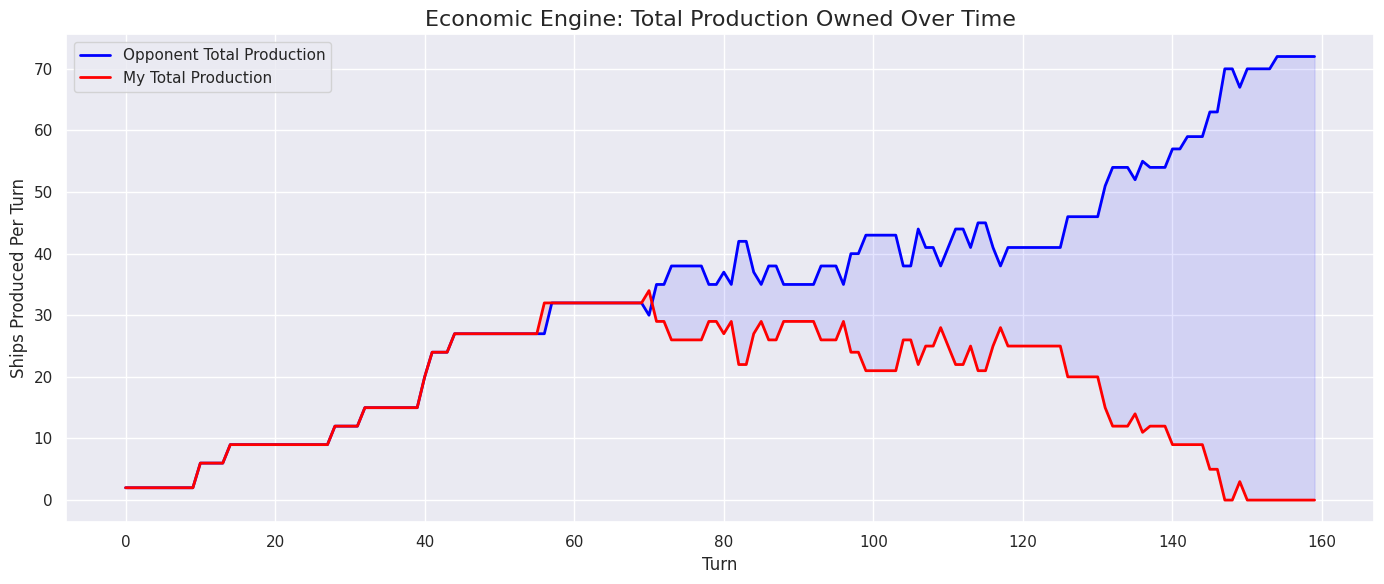

In [7]:
# Cell: Planet Production Ownership Over Time
production_data = []

for turn_idx, step in enumerate(steps):
    obs = step[0]['observation']
    planets = obs['planets']
    
    # p[6] is production, p[1] is owner
    p0_prod = sum(p[6] for p in planets if p[1] == 0)
    p1_prod = sum(p[6] for p in planets if p[1] == 1)
    
    production_data.append({
        'turn': turn_idx,
        'P0_Production': p0_prod,
        'P1_Production': p1_prod
    })

df_prod = pd.DataFrame(production_data)

plt.figure(figsize=(14, 6))
plt.plot(df_prod['turn'], df_prod['P1_Production'], label='Opponent Total Production', color='blue', linewidth=2)
plt.plot(df_prod['turn'], df_prod['P0_Production'], label='My Total Production', color='red', linewidth=2)

# Highlight area where one player has a massive advantage
plt.fill_between(df_prod['turn'], df_prod['P0_Production'], df_prod['P1_Production'], 
                 where=(df_prod['P0_Production'] > df_prod['P1_Production']), 
                 interpolate=True, color='red', alpha=0.1)
plt.fill_between(df_prod['turn'], df_prod['P0_Production'], df_prod['P1_Production'], 
                 where=(df_prod['P1_Production'] > df_prod['P0_Production']), 
                 interpolate=True, color='blue', alpha=0.1)

plt.title('Economic Engine: Total Production Owned Over Time', fontsize=16)
plt.xlabel('Turn', fontsize=12)
plt.ylabel('Ships Produced Per Turn', fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()

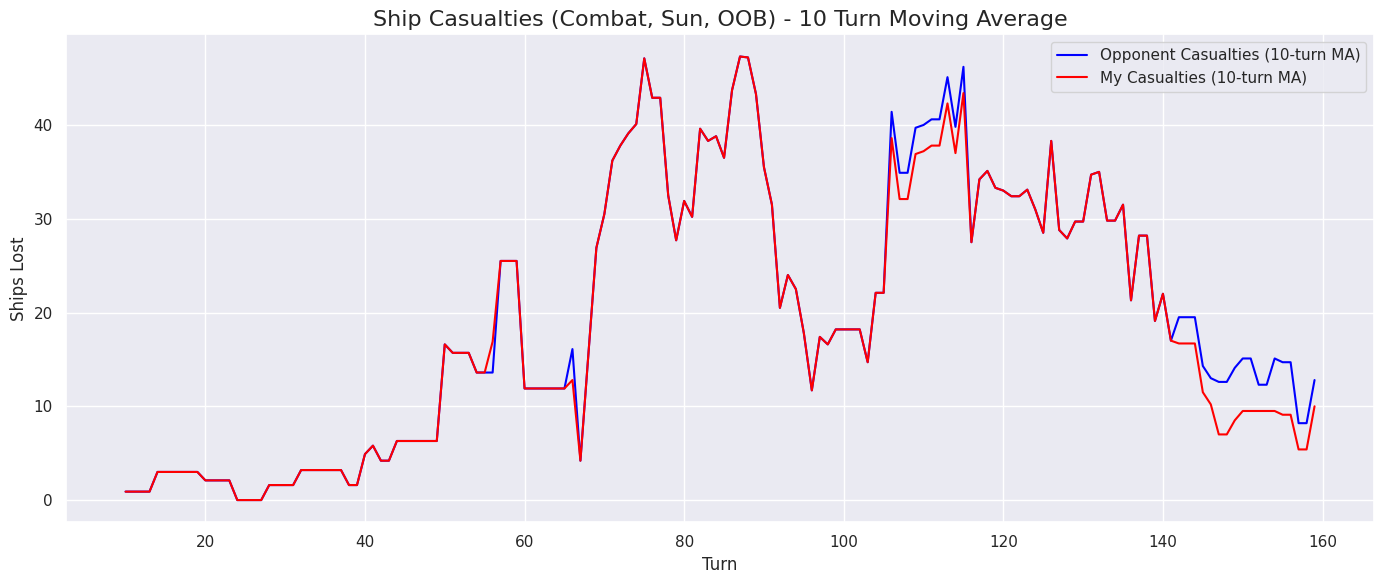

In [8]:
# Cell: Combat Losses and Unforced Errors (Ship Delta)
loss_data = []

prev_p0_total = 0
prev_p1_total = 0
prev_p0_prod = 0
prev_p1_prod = 0

for turn_idx, step in enumerate(steps):
    obs = step[0]['observation']
    planets = obs['planets']
    fleets = obs.get('fleets', [])
    
    # Current totals
    p0_planet_ships = sum(p[5] for p in planets if p[1] == 0)
    p1_planet_ships = sum(p[5] for p in planets if p[1] == 1)
    p0_fleet_ships = sum(f[6] for f in fleets if f[1] == 0)
    p1_fleet_ships = sum(f[6] for f in fleets if f[1] == 1)
    
    current_p0_total = p0_planet_ships + p0_fleet_ships
    current_p1_total = p1_planet_ships + p1_fleet_ships
    
    if turn_idx > 0:
        # Expected = previous total + previous production
        p0_expected = prev_p0_total + prev_p0_prod
        p1_expected = prev_p1_total + prev_p1_prod
        
        # Losses = Expected - Actual
        p0_losses = max(0, p0_expected - current_p0_total)
        p1_losses = max(0, p1_expected - current_p1_total)
        
        loss_data.append({
            'turn': turn_idx,
            'P0_Casualties': p0_losses,
            'P1_Casualties': p1_losses
        })
        
    # Set prev values for next iteration
    prev_p0_total = current_p0_total
    prev_p1_total = current_p1_total
    prev_p0_prod = sum(p[6] for p in planets if p[1] == 0)
    prev_p1_prod = sum(p[6] for p in planets if p[1] == 1)

df_losses = pd.DataFrame(loss_data)

plt.figure(figsize=(14, 6))
plt.plot(df_losses['turn'], df_losses['P1_Casualties'].rolling(10).mean(), label='Opponent Casualties (10-turn MA)', color='blue')
plt.plot(df_losses['turn'], df_losses['P0_Casualties'].rolling(10).mean(), label='My Casualties (10-turn MA)', color='red')
plt.title('Ship Casualties (Combat, Sun, OOB) - 10 Turn Moving Average', fontsize=16)
plt.xlabel('Turn', fontsize=12)
plt.ylabel('Ships Lost', fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()

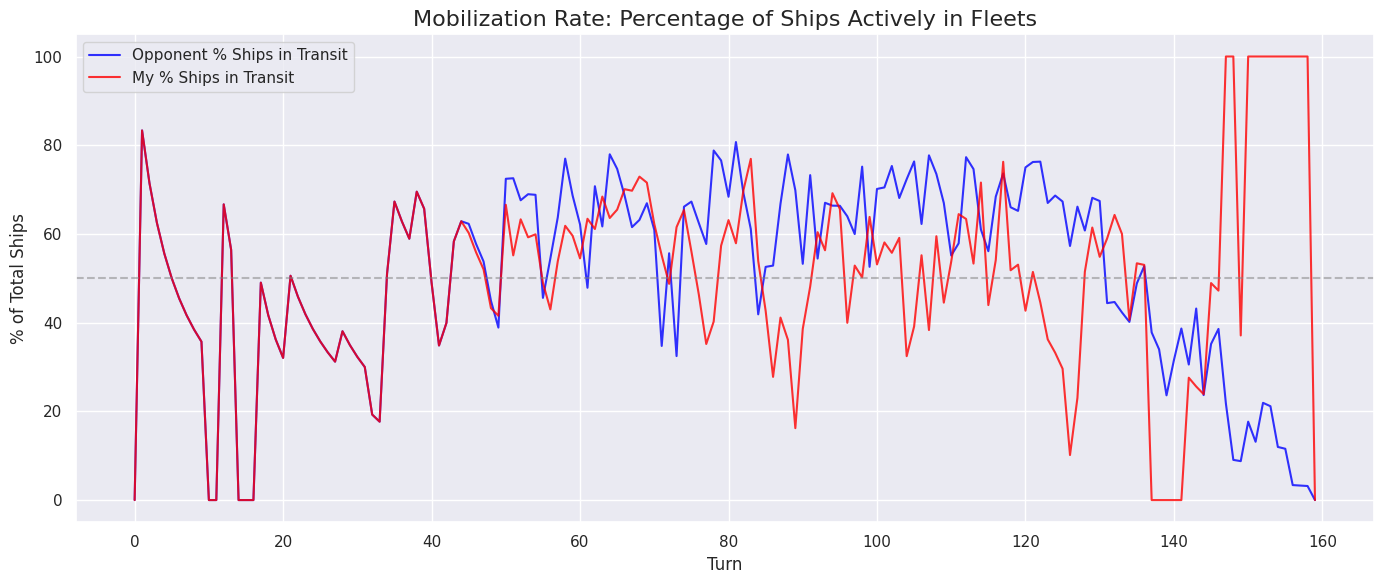

In [9]:
# Cell: Resource Utilization (Percentage of Ships in Transit)
utilization_data = []

for turn_idx, step in enumerate(steps):
    obs = step[0]['observation']
    planets = obs['planets']
    fleets = obs.get('fleets', [])
    
    p0_planet = sum(p[5] for p in planets if p[1] == 0)
    p0_fleet = sum(f[6] for f in fleets if f[1] == 0)
    p0_total = p0_planet + p0_fleet
    
    p1_planet = sum(p[5] for p in planets if p[1] == 1)
    p1_fleet = sum(f[6] for f in fleets if f[1] == 1)
    p1_total = p1_planet + p1_fleet
    
    utilization_data.append({
        'turn': turn_idx,
        'P0_Active_Pct': (p0_fleet / p0_total * 100) if p0_total > 0 else 0,
        'P1_Active_Pct': (p1_fleet / p1_total * 100) if p1_total > 0 else 0,
    })

df_util = pd.DataFrame(utilization_data)

plt.figure(figsize=(14, 6))
plt.plot(df_util['turn'], df_util['P1_Active_Pct'], label='Opponent % Ships in Transit', color='blue', alpha=0.8)
plt.plot(df_util['turn'], df_util['P0_Active_Pct'], label='My % Ships in Transit', color='red', alpha=0.8)
plt.axhline(y=50, color='gray', linestyle='--', alpha=0.5)
plt.title('Mobilization Rate: Percentage of Ships Actively in Fleets', fontsize=16)
plt.xlabel('Turn', fontsize=12)
plt.ylabel('% of Total Ships', fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()

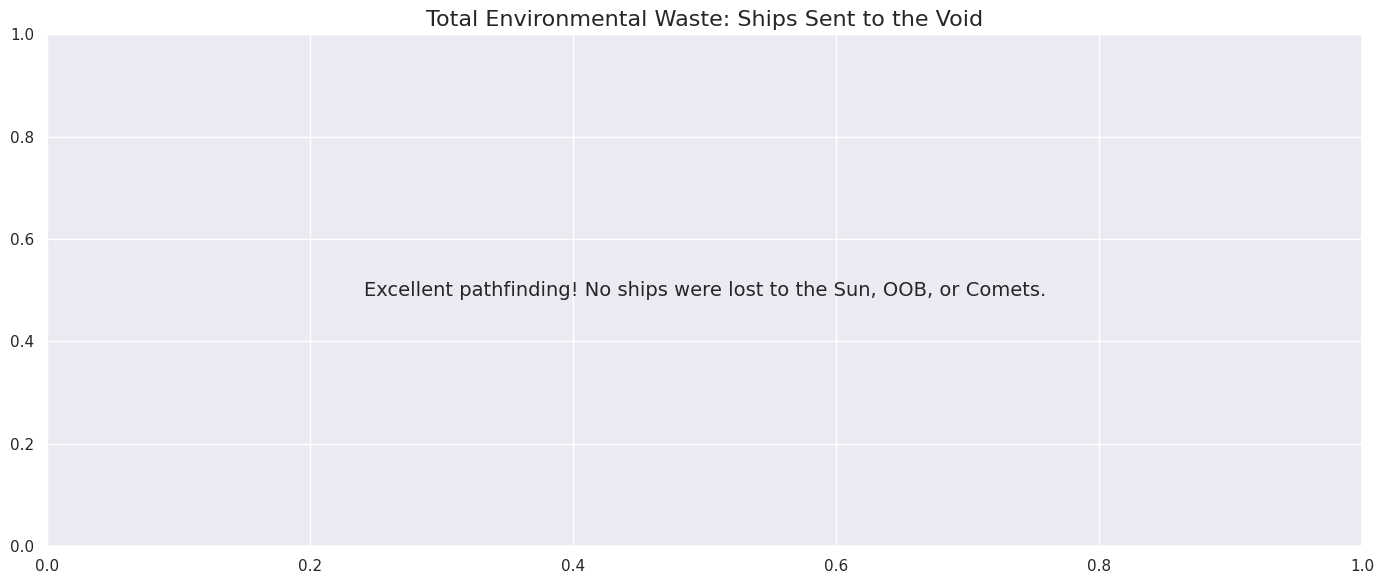

In [10]:
# Cell: Comprehensive Void Loss Tracker (Sun, Out-of-Bounds, and Comet Expirations)
import math

void_loss_data = []
prev_comet_ships = {}  # {planet_id: (owner, ships)}
tracked_fleets = {}    # {fleet_id: (owner, ships, x, y, angle)}

for turn_idx, step in enumerate(steps):
    obs = step[0]['observation']
    planets = obs['planets']
    fleets = obs.get('fleets', [])
    comet_ids = set(obs.get('comet_planet_ids', []))
    
    p0_comet_void = 0
    p1_comet_void = 0
    p0_fleet_void = 0
    p1_fleet_void = 0
    
    # 1. Track Comet Expiration Losses
    current_comets = {p[0]: (p[1], p[5]) for p in planets if p[0] in comet_ids}
    for c_id, (owner, ships) in prev_comet_ships.items():
        if c_id not in current_comets:
            if owner == 0: p0_comet_void += ships
            elif owner == 1: p1_comet_void += ships
    prev_comet_ships = current_comets

    # 2. Track Fleet Environment Deletions (Sun / Out-of-Bounds)
    current_fleets = {f[0]: (f[1], f[6], f[2], f[3], f[4]) for f in fleets}
    
    # Check fleets from previous turn that disappeared this turn
    for f_id, (owner, ships, x, y, angle) in tracked_fleets.items():
        if f_id not in current_fleets:
            # Predict where it was heading to see if it hit an environmental hazard
            # Max speed is 6.0, base is 1.0
            log_ratio = max(0.0, math.log(max(1, ships)) / math.log(1000))
            speed = 1.0 + 5.0 * (log_ratio ** 1.5)
            
            next_x = x + speed * math.cos(angle)
            next_y = y + speed * math.sin(angle)
            
            # Check Out of Bounds
            oob = next_x < 0 or next_x > 100 or next_y < 0 or next_y > 100
            
            # Check Sun Collision (Distance to center (50,50) < 10)
            # Standard continuous collision can be simplified by checking closest point on segment, 
            # but checking next step center-distance covers direct fly-ins accurately enough for EDA
            dist_to_sun = math.hypot(next_x - 50, next_y - 50)
            hit_sun = dist_to_sun <= 10.0
            
            if oob or hit_sun:
                if owner == 0: p0_fleet_void += ships
                elif owner == 1: p1_fleet_void += ships
                
    tracked_fleets = current_fleets
    
    if p0_comet_void > 0 or p1_comet_void > 0 or p0_fleet_void > 0 or p1_fleet_void > 0:
        void_loss_data.append({
            'turn': turn_idx,
            'P0_Comet_Void': p0_comet_void,
            'P1_Comet_Void': p1_comet_void,
            'P0_Fleet_Void': p0_fleet_void,
            'P1_Fleet_Void': p1_fleet_void,
            'P0_Total_Void': p0_comet_void + p0_fleet_void,
            'P1_Total_Void': p1_comet_void + p1_fleet_void
        })

df_void = pd.DataFrame(void_loss_data)

# Plotting the Cumulative Environmental Waste
plt.figure(figsize=(14, 6))

if not df_void.empty:
    # Calculate cumulative losses to show the macro bleed over the course of the game
    df_void['P0_Cum_Void'] = df_void['P0_Total_Void'].cumsum()
    df_void['P1_Cum_Void'] = df_void['P1_Total_Void'].cumsum()
    
    plt.plot(df_void['turn'], df_void['P1_Cum_Void'], label='Opponent Cumulative Void Losses', color='blue', linewidth=2.5)
    plt.plot(df_void['turn'], df_void['P0_Cum_Void'], label='My Cumulative Void Losses', color='red', linewidth=2.5)
    
    # Scatter individual disaster turns (spikes where fleets hit the sun or comets expired)
    plt.scatter(df_void['turn'], df_void['P1_Total_Void'], color='blue', alpha=0.4, marker='x', label='Opponent Single-Turn Void Event')
    plt.scatter(df_void['turn'], df_void['P0_Total_Void'], color='red', alpha=0.4, marker='o', label='My Single-Turn Void Event')
    
    plt.title('Total Environmental Waste: Ships Sent to the Void (Sun, OOB, Comet Expiration)', fontsize=16)
    plt.xlabel('Turn', fontsize=12)
    plt.ylabel('Cumulative Ship Count', fontsize=12)
    plt.legend()
else:
    plt.text(0.5, 0.5, 'Excellent pathfinding! No ships were lost to the Sun, OOB, or Comets.', 
             horizontalalignment='center', verticalalignment='center', fontsize=14)
    plt.title('Total Environmental Waste: Ships Sent to the Void', fontsize=16)

plt.tight_layout()
plt.show()

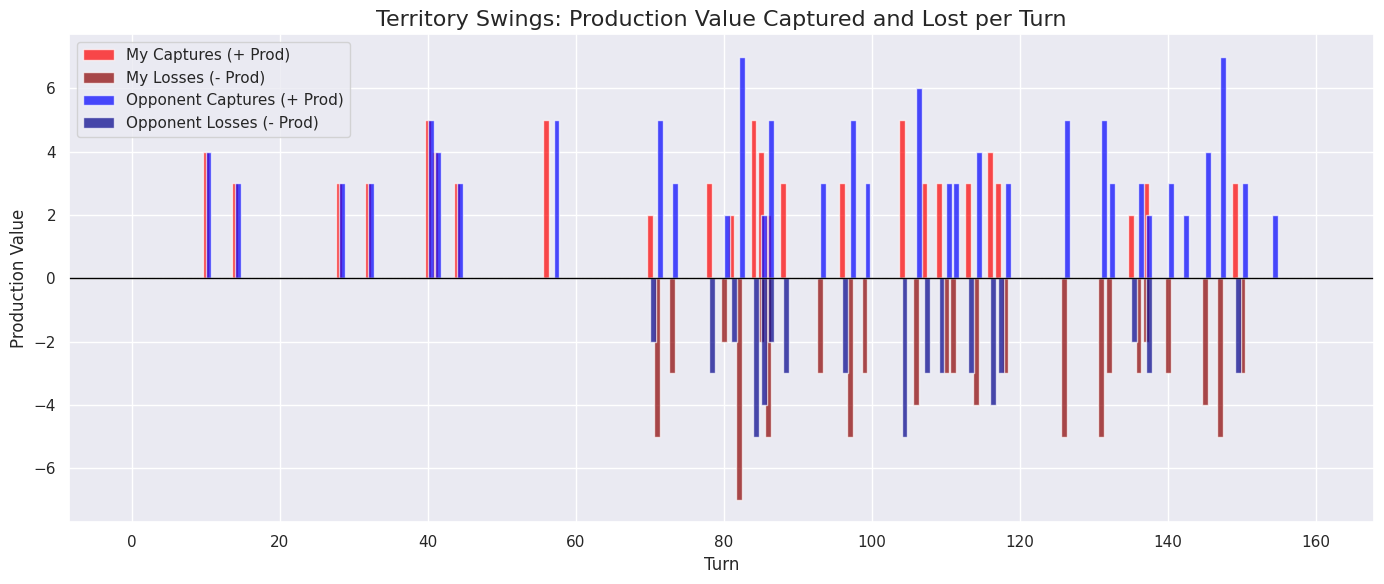

In [11]:
# Cell: Frontline Shifts (Production Captured vs Lost)
combat_events_data = []
prev_planets = {} # {id: (owner, ships, prod)}

for turn_idx, step in enumerate(steps):
    obs = step[0]['observation']
    current_planets = {p[0]: p for p in obs['planets']}
    
    p0_prod_captured = 0
    p1_prod_captured = 0
    p0_prod_lost = 0
    p1_prod_lost = 0
    
    if turn_idx > 0:
        for pid, p in current_planets.items():
            if pid in prev_planets:
                prev_owner, prev_ships, prev_prod = prev_planets[pid]
                curr_owner, curr_ships, curr_prod = p[1], p[5], p[6]
                
                if prev_owner != curr_owner:
                    # Capture Success!
                    if curr_owner == 0: p0_prod_captured += curr_prod
                    elif curr_owner == 1: p1_prod_captured += curr_prod
                    
                    # Capture Lost!
                    if prev_owner == 0: p0_prod_lost += prev_prod
                    elif prev_owner == 1: p1_prod_lost += prev_prod

    turn_events = {
        'turn': turn_idx,
        'P0_Captured': p0_prod_captured,
        'P1_Captured': p1_prod_captured,
        'P0_Lost': -p0_prod_lost, # Negative for plotting
        'P1_Lost': -p1_prod_lost  # Negative for plotting
    }
    combat_events_data.append(turn_events)
    
    prev_planets = {pid: (p[1], p[5], p[6]) for pid, p in current_planets.items()}

df_territory = pd.DataFrame(combat_events_data)

plt.figure(figsize=(14, 6))

# Plot My Player (P0)
plt.bar(df_territory['turn'], df_territory['P0_Captured'], color='red', alpha=0.7, label='My Captures (+ Prod)')
plt.bar(df_territory['turn'], df_territory['P0_Lost'], color='darkred', alpha=0.7, label='My Losses (- Prod)')

# Plot Opponent (P1) - slightly offset for visibility if they happen on the same turn
plt.bar(df_territory['turn'] + 0.4, df_territory['P1_Captured'], color='blue', alpha=0.7, label='Opponent Captures (+ Prod)')
plt.bar(df_territory['turn'] + 0.4, df_territory['P1_Lost'], color='darkblue', alpha=0.7, label='Opponent Losses (- Prod)')

plt.axhline(0, color='black', linewidth=1)
plt.title('Territory Swings: Production Value Captured and Lost per Turn', fontsize=16)
plt.xlabel('Turn', fontsize=12)
plt.ylabel('Production Value', fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()

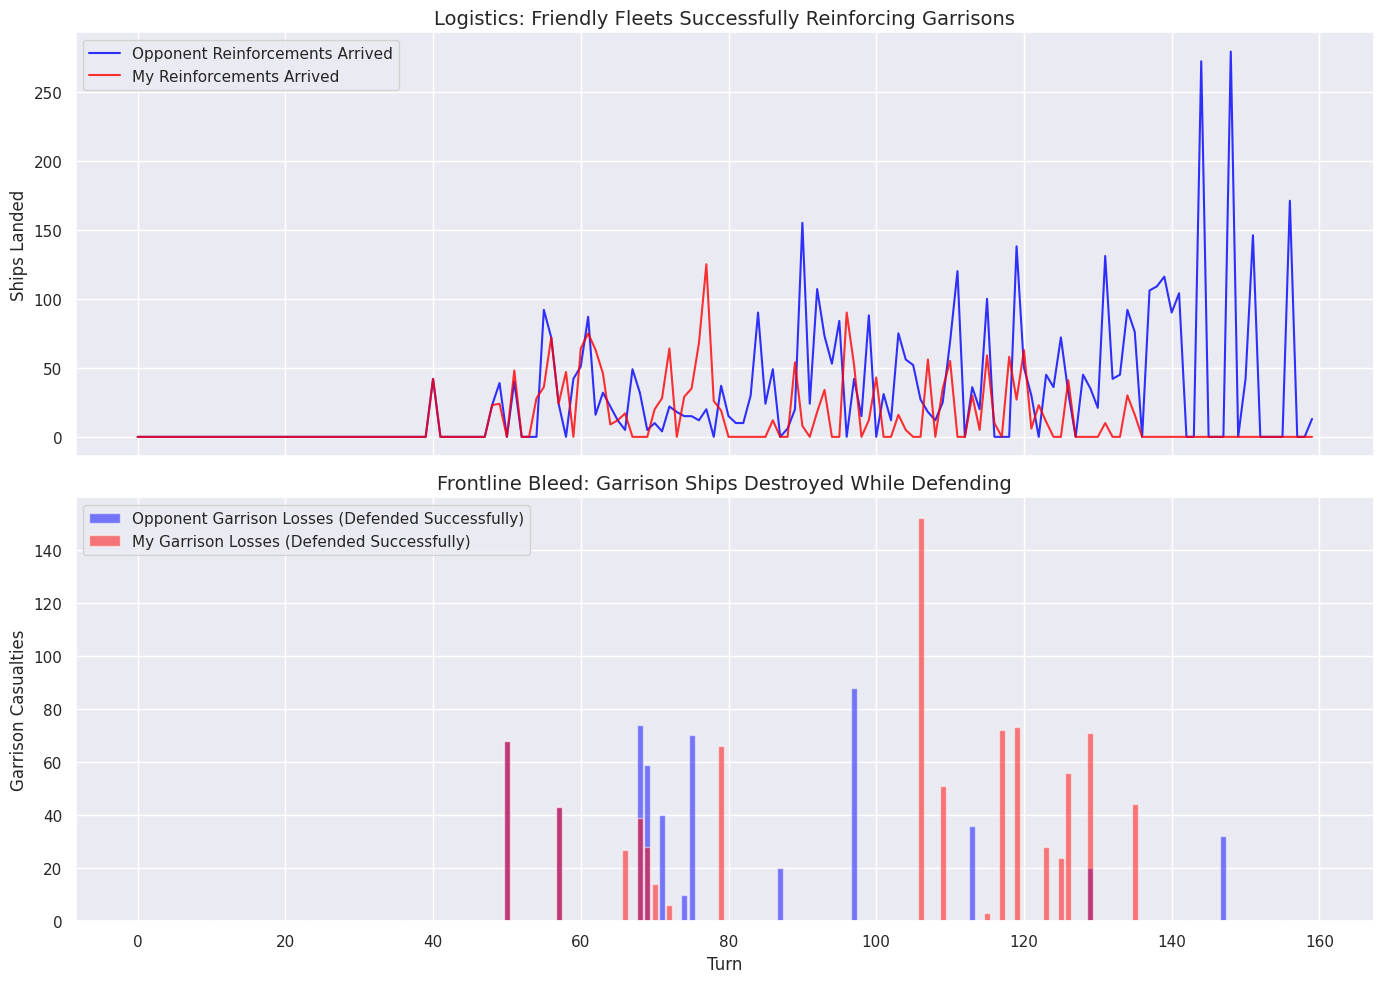

In [ ]:
# Cell: Planetary Logistics (Reinforcements Landed & Defensive Damage Taken)
logistics_data = []
prev_planets = {}
seen_fleets = set()

for turn_idx, step in enumerate(steps):
    obs = step[0]['observation']
    current_planets = {p[0]: p for p in obs['planets']}
    fleets = obs.get('fleets', [])
    
    # 1. Tally Launches for this turn
    launches = {}
    for f in fleets:
        f_id, owner, x, y, angle, from_pid, ships = f[0], f[1], f[2], f[3], f[4], f[5], f[6]
        if f_id not in seen_fleets:
            seen_fleets.add(f_id)
            launches[from_pid] = launches.get(from_pid, 0) + ships

    p0_reinf, p1_reinf = 0, 0
    p0_def_dmg, p1_def_dmg = 0, 0
    
    if turn_idx > 0:
        for pid, p in current_planets.items():
            if pid in prev_planets:
                prev_owner, prev_ships, prev_prod = prev_planets[pid]
                curr_owner, curr_ships, curr_prod = p[1], p[5], p[6]
                
                # We only check reinforcements/defenses on planets that DID NOT change ownership
                if prev_owner == curr_owner and curr_owner != -1:
                    launched_this_turn = launches.get(pid, 0)
                    
                    # Expected = Previous Garrison + New Ships - Ships that left
                    expected_garrison = prev_ships + prev_prod - launched_this_turn
                    delta = curr_ships - expected_garrison
                    
                    if delta > 0: # More ships than expected = Reinforcements arrived
                        if curr_owner == 0: p0_reinf += delta
                        elif curr_owner == 1: p1_reinf += delta
                    elif delta < 0: # Fewer ships than expected = Garrison absorbed an attack
                        if curr_owner == 0: p0_def_dmg += abs(delta)
                        elif curr_owner == 1: p1_def_dmg += abs(delta)

    logistics_data.append({
        'turn': turn_idx,
        'P0_Reinforcements': p0_reinf,
        'P1_Reinforcements': p1_reinf,
        'P0_Defensive_Damage': p0_def_dmg,
        'P1_Defensive_Damage': p1_def_dmg
    })
    
    prev_planets = {pid: (p[1], p[5], p[6]) for pid, p in current_planets.items()}

df_logistics = pd.DataFrame(logistics_data)

fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True)

# Subplot 1: Reinforcements
axes[0].plot(df_logistics['turn'], df_logistics['P1_Reinforcements'], color='blue', label='Opponent Reinforcements Arrived', alpha=0.8)
axes[0].plot(df_logistics['turn'], df_logistics['P0_Reinforcements'], color='red', label='My Reinforcements Arrived', alpha=0.8)
axes[0].set_title('Logistics: Friendly Fleets Successfully Reinforcing Garrisons', fontsize=14)
axes[0].set_ylabel('Ships Landed', fontsize=12)
axes[0].legend()

# Subplot 2: Defensive Damage Taken
axes[1].bar(df_logistics['turn'], df_logistics['P1_Defensive_Damage'], color='blue', alpha=0.5, label='Opponent Garrison Losses (Defended Successfully)')
axes[1].bar(df_logistics['turn'], df_logistics['P0_Defensive_Damage'], color='red', alpha=0.5, label='My Garrison Losses (Defended Successfully)')
axes[1].set_title('Frontline Bleed: Garrison Ships Destroyed While Defending', fontsize=14)
axes[1].set_xlabel('Turn', fontsize=12)
axes[1].set_ylabel('Garrison Casualties', fontsize=12)
axes[1].legend()

plt.tight_layout()
plt.show()

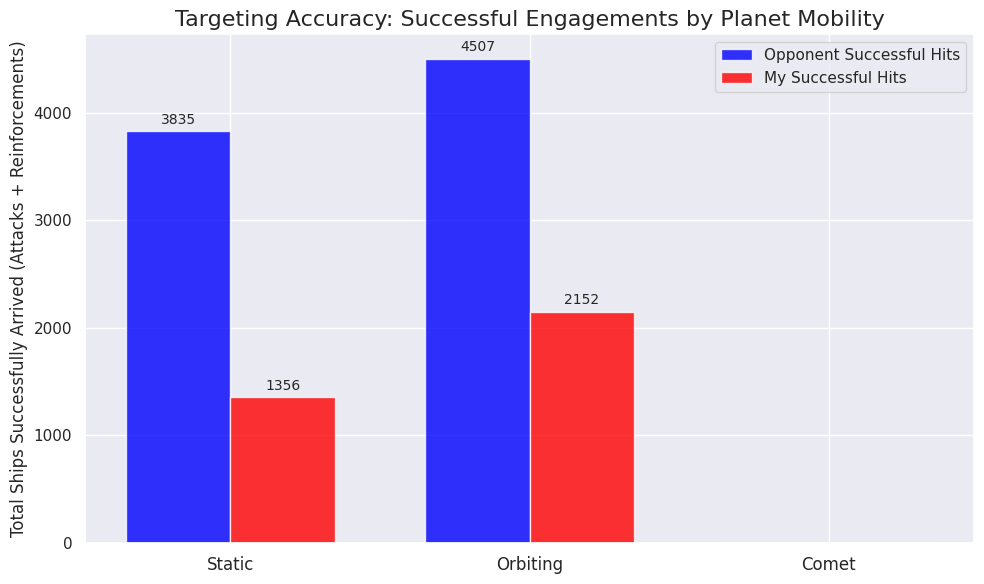

In [ ]:
# Cell: Orbital vs Static Targeting Accuracy (Successful Hits)
import math
import numpy as np

# Step 1: Classify Planets at game start
initial_planets = steps[0][0]['observation']['planets']
planet_mobility = {} # {pid: 'Static', 'Orbiting', or 'Comet'}

for p in initial_planets:
    pid, x, y, r = p[0], p[2], p[3], p[4]
    dist_to_sun = math.hypot(x - 50, y - 50)
    # Orbit wars rule: orbital_radius + planet_radius < 50 means it orbits
    if dist_to_sun + r < 50:
        planet_mobility[pid] = 'Orbiting'
    else:
        planet_mobility[pid] = 'Static'

target_hit_data = []
prev_planets = {}
seen_fleets = set()

# Trackers for total successful arrivals (attacks + reinforcements) per category
p0_hits = {'Static': 0, 'Orbiting': 0, 'Comet': 0}
p1_hits = {'Static': 0, 'Orbiting': 0, 'Comet': 0}

for turn_idx, step in enumerate(steps):
    obs = step[0]['observation']
    current_planets = {p[0]: p for p in obs['planets']}
    fleets = obs.get('fleets', [])
    comet_ids = set(obs.get('comet_planet_ids', []))
    
    # Update mobility map for newly spawned comets
    for cid in comet_ids:
        if cid not in planet_mobility:
            planet_mobility[cid] = 'Comet'
            
    # Tally Launches for this turn
    launches = {}
    for f in fleets:
        if f[0] not in seen_fleets:
            seen_fleets.add(f[0])
            launches[f[5]] = launches.get(f[5], 0) + f[6]

    if turn_idx > 0:
        for pid, p in current_planets.items():
            if pid in prev_planets:
                prev_owner, prev_ships, prev_prod = prev_planets[pid]
                curr_owner, curr_ships, curr_prod = p[1], p[5], p[6]
                
                mobility = planet_mobility.get(pid, 'Static')
                launched_this_turn = launches.get(pid, 0)
                
                # Expected garrison if NO combat happened
                expected_garrison = max(0, prev_ships + prev_prod - launched_this_turn)

                if prev_owner == curr_owner and curr_owner != -1:
                    delta = curr_ships - expected_garrison
                    if delta > 0:
                        # Friendly reinforcements landed
                        if curr_owner == 0: p0_hits[mobility] += delta
                        elif curr_owner == 1: p1_hits[mobility] += delta
                    elif delta < 0:
                        # Enemy attack hit, but garrison survived
                        # The attacker lost 'abs(delta)' ships on impact
                        attacker = 1 if curr_owner == 0 else 0
                        if attacker == 0: p0_hits[mobility] += abs(delta)
                        elif attacker == 1: p1_hits[mobility] += abs(delta)
                        
                elif prev_owner != curr_owner and curr_owner != -1:
                    # Planet was captured!
                    # The attacker had to destroy the expected garrison AND have curr_ships remaining
                    attacking_ships_arrived = expected_garrison + curr_ships
                    if curr_owner == 0: p0_hits[mobility] += attacking_ships_arrived
                    elif curr_owner == 1: p1_hits[mobility] += attacking_ships_arrived

    prev_planets = {pid: (p[1], p[5], p[6]) for pid, p in current_planets.items()}

# Prepare data for plotting
categories = ['Static', 'Orbiting', 'Comet']
p0_values = [p0_hits[cat] for cat in categories]
p1_values = [p1_hits[cat] for cat in categories]

x = np.arange(len(categories))
width = 0.35

plt.figure(figsize=(10, 6))
bars1 = plt.bar(x - width/2, p1_values, width, label='Opponent Successful Hits', color='blue', alpha=0.8)
bars2 = plt.bar(x + width/2, p0_values, width, label='My Successful Hits', color='red', alpha=0.8)

# Add value labels on top of bars
def add_labels(bars):
    for bar in bars:
        height = bar.get_height()
        if height > 0:
            plt.annotate(f'{int(height)}',
                        xy=(bar.get_x() + bar.get_width() / 2, height),
                        xytext=(0, 3),  # 3 points vertical offset
                        textcoords="offset points",
                        ha='center', va='bottom', fontsize=10)

add_labels(bars1)
add_labels(bars2)

plt.ylabel('Total Ships Successfully Arrived (Attacks + Reinforcements)', fontsize=12)
plt.title('Targeting Accuracy: Successful Engagements by Planet Mobility', fontsize=16)
plt.xticks(x, categories, fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()